In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import periodogram, welch

## Make data

In [160]:
nt = 1000
N = 100000
dt = 0.02

signals = np.random.randn(N, nt)
tvec = np.arange(nt)*dt

## Periodogram

In [161]:
fs, spectra = periodogram(signals, fs=1/dt, axis=1)

In [162]:
fs = fs[1:-1]
spectra = spectra[:, 1:-1]

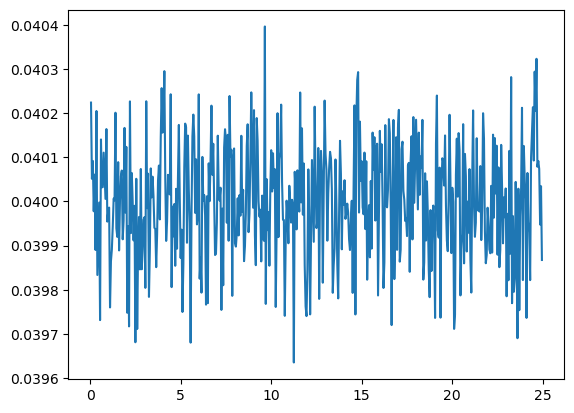

In [163]:
f,ax = plt.subplots()
ax.plot(fs, spectra.mean(axis=0))

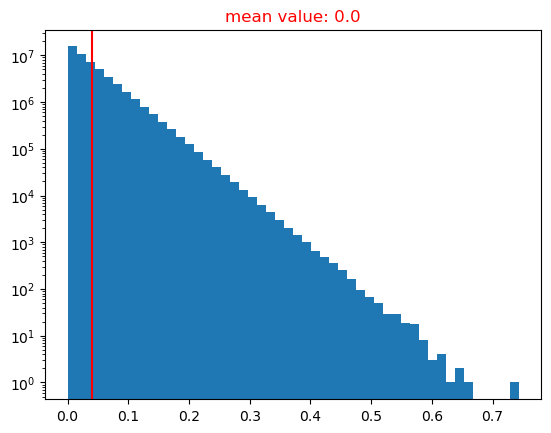

In [164]:
plt.hist(spectra.ravel(), bins=50);
plt.axvline(spectra.mean(), color='r')
plt.title(f"mean value: {spectra.mean():.1f}", color='r')
plt.yscale('log')

## We want to test the significance of power integrated in a frequency band, estimating the noise floor from the spectrum

In [165]:
from scipy.stats import f as f_dist

In [232]:

def test_integrated_power(psd, freq, fs, band, reference_band):

    val = (freq >= band[0]) & (freq <= band[1])
    ref = (freq >= reference_band[0]) & (freq <= reference_band[1])


    if np.any(val & ref):
        raise ValueError("Bands must not overlap")

    mt = np.sum(val)
    mr = np.sum(ref)
    # print(mt, mr)
    if mt == 0 or mr == 0:
        raise ValueError("Frequency bands contain no valid bins")

    # Compare mean spectral densities
    F = np.mean(psd[val]) / np.mean(psd[ref])

    p = f_dist.sf(F, 2 * mt, 2 * mr)

    power_int = np.trapz(psd[val], freq[val])

    return power_int, F, p, mt, mr

In [233]:

F_values = []
p_vals = []
for sp in spectra:
    power, F, p, mt, mr = test_integrated_power(
        sp, freq=fs, fs=1/dt,
        band=(1, 1.2),
        reference_band=(3,3.5)
    )
    F_values.append(F)
    p_vals.append(p)

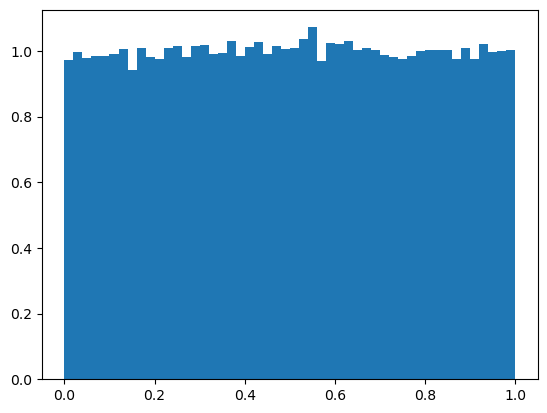

In [234]:
plt.hist(p_vals, bins=50, density=True);

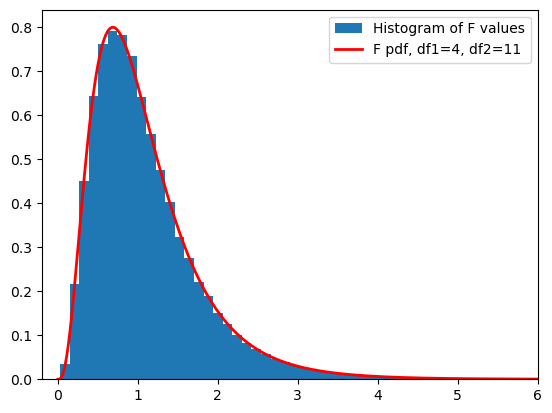

In [242]:
f,ax = plt.subplots()
ax.hist(F_values, bins=100, density=True, label='Histogram of F values');

d1, d2 = 2*mt, 2*mr

x_vals = np.arange(0, 10, 0.01)
pdf = f_dist.pdf(x_vals, d1, d2)

ax.plot(x_vals, pdf, linewidth=2, color='r', label=f"F pdf, df1={mt}, df2={mr}")
ax.set_xlim(-0.2,6)
ax.legend()